In [ ]:
from pathlib import Path
import warnings
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    f1_score,
    accuracy_score,
    roc_curve
)

# -------------------------------
# Configuration
# -------------------------------
RANDOM_STATE = 42
TEST_SIZE = 0.2

DATASET_FILE_PATH_STR = '/content/drive/MyDrive/PS_20174392719_1491204439457_log.csv'
DATASET_FOLDER_PATH_STR = Path(DATASET_FILE_PATH_STR).parent

warnings.filterwarnings('ignore')
print("✅ Libraries imported successfully!")

✅ Libraries imported successfully!


In [ ]:
import pandas as pd
df = pd.read_csv(DATASET_FILE_PATH_STR.strip())

print("="*60)
print("DATASET OVERVIEW")
print("="*60)
print(f"📊 Shape: {df.shape[0]:,} transactions, {df.shape[1]} features")
print(f"\n📋 Columns: {df.columns.tolist()}")
print(f"\n📈 Sample Data:")
df.head()

DATASET OVERVIEW
📊 Shape: 1,048,575 transactions, 11 features

📋 Columns: ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

📈 Sample Data:


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = df.copy()

In [ ]:
print("\n🔍 Missing Values:")
df.isnull().sum()


🔍 Missing Values:


,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


In [ ]:
# Dataset Statistics (Relevant Features Only)
print("📊 Statistical Summary (Selected Features):")
df[['step', 'amount', 'isFraud', 'isFlaggedFraud']].describe()

📊 Statistical Summary (Selected Features):


,step,amount,isFraud,isFlaggedFraud
count,1.048575e+06,1.048575e+06,1.048575e+06,1048575.0
mean,2.696617e+01,1.586670e+05,1.089097e-03,0.0
std,1.562325e+01,2.649409e+05,3.298351e-02,0.0
min,1.000000e+00,1.000000e-01,0.000000e+00,0.0
25%,1.500000e+01,1.214907e+04,0.000000e+00,0.0
50%,2.000000e+01,7.634333e+04,0.000000e+00,0.0
75%,3.900000e+01,2.137619e+05,0.000000e+00,0.0
max,9.500000e+01,1.000000e+07,1.000000e+00,0.0


FRAUD DISTRIBUTION ANALYSIS

🔢 Transaction Counts:
   Non-Fraud: 1,047,433
   Fraud: 1,142

📊 Fraud Rate: 0.1089%


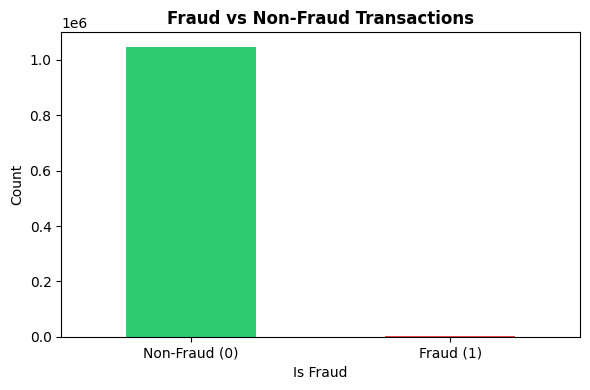

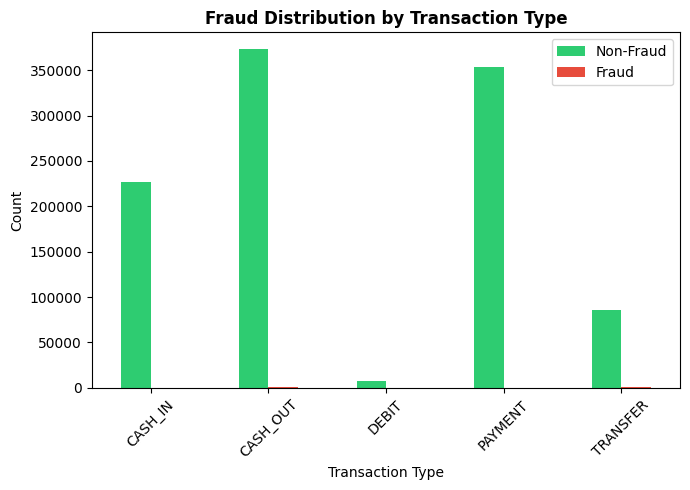

In [ ]:
# Fraud Distribution Analysis
print("="*60)
print("FRAUD DISTRIBUTION ANALYSIS")
print("="*60)

# Class distribution
fraud_counts = df['isFraud'].value_counts()
fraud_rate = df['isFraud'].mean() * 100

print(f"\n🔢 Transaction Counts:")
print(f"   Non-Fraud: {fraud_counts[0]:,}")
print(f"   Fraud: {fraud_counts[1]:,}")
print(f"\n📊 Fraud Rate: {fraud_rate:.4f}%")

# -------------------- Visualization --------------------

# Plot 1: Fraud vs Non-Fraud distribution
plt.figure(figsize=(6,4))
fraud_counts.plot(kind='bar', color=['#2ecc71', '#e74c3c'])
plt.title('Fraud vs Non-Fraud Transactions', fontsize=12, fontweight='bold')
plt.xlabel('Is Fraud')
plt.ylabel('Count')
plt.xticks([0,1], ['Non-Fraud (0)', 'Fraud (1)'], rotation=0)
plt.tight_layout()
plt.savefig('fig_fraud_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# Plot 2: Fraud distribution by transaction type
fraud_by_type = pd.crosstab(df['type'], df['isFraud'])

fraud_by_type.plot(
    kind='bar',
    figsize=(7,5),
    color=['#2ecc71', '#e74c3c']
)
plt.title('Fraud Distribution by Transaction Type', fontsize=12, fontweight='bold')
plt.xlabel('Transaction Type')
plt.ylabel('Count')
plt.legend(['Non-Fraud', 'Fraud'])
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('fig_fraud_by_type.png', dpi=150, bbox_inches='tight')
plt.show()

FRAUD ANALYSIS BY TRANSACTION TYPE
          Fraud_Count  Total_Count  Fraud_Rate
type                                          
CASH_IN             0       227130    0.000000
CASH_OUT          578       373641    0.154694
DEBIT               0         7178    0.000000
PAYMENT             0       353873    0.000000
TRANSFER          564        86753    0.650122


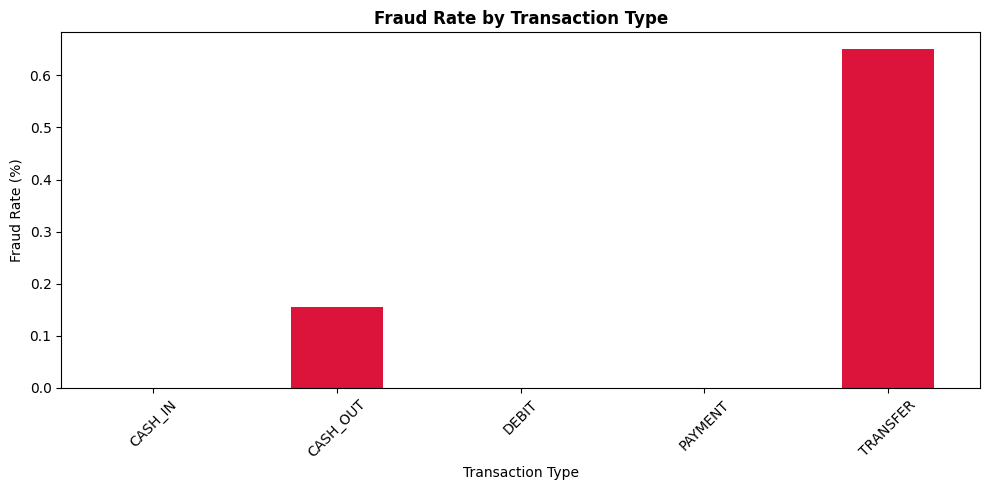


📌 Key Finding: Fraud occurs exclusively in CASH_OUT and TRANSFER transactions.


In [ ]:
print("="*60)
print("FRAUD ANALYSIS BY TRANSACTION TYPE")
print("="*60)

fraud_by_type = df.groupby('type')['isFraud'].agg(['sum', 'count', 'mean'])
fraud_by_type.columns = ['Fraud_Count', 'Total_Count', 'Fraud_Rate']
fraud_by_type['Fraud_Rate'] = fraud_by_type['Fraud_Rate'] * 100

print(fraud_by_type)

# Visualization
fig, ax = plt.subplots(figsize=(10, 5))
fraud_by_type['Fraud_Rate'].plot(kind='bar', ax=ax, color='crimson')
ax.set_title('Fraud Rate by Transaction Type', fontsize=12, fontweight='bold')
ax.set_xlabel('Transaction Type')
ax.set_ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('fig_fraud_by_type.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n📌 Key Finding: Fraud occurs exclusively in CASH_OUT and TRANSFER transactions.")

In [ ]:
# Feature Selection & Safe Feature Engineering
print("="*60)
print("FEATURE SELECTION & ENGINEERING")
print("="*60)

# -------------------------------
# Drop leakage-prone balance features
# -------------------------------
leakage_features = [
    'oldbalanceOrg', 'newbalanceOrig',
    'oldbalanceDest', 'newbalanceDest'
]

df_fe = df.drop(columns=leakage_features)

print(f"🗑 Dropped leakage-prone features: {leakage_features}")

# -------------------------------
# Safe feature engineering
# -------------------------------

# Binary flags for high-risk transaction types
df_fe['isTransfer'] = (df_fe['type'] == 'TRANSFER').astype(int)
df_fe['isCashOut'] = (df_fe['type'] == 'CASH_OUT').astype(int)

# Log-scaled transaction amount (handles skewness)
df_fe['logAmount'] = np.log1p(df_fe['amount'])

# Time-based feature (hour of transaction)
df_fe['hour'] = df_fe['step'] % 24

print("✅ Safe features created successfully!")

print("\n📋 Final feature set:")
print(df_fe.columns.tolist())
print(f"\n📊 Total features after engineering: {df_fe.shape[1]}")

FEATURE SELECTION & ENGINEERING
🗑 Dropped leakage-prone features: ['oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
✅ Safe features created successfully!

📋 Final feature set:
['step', 'type', 'amount', 'nameOrig', 'nameDest', 'isFraud', 'isFlaggedFraud', 'isTransfer', 'isCashOut', 'logAmount', 'hour']

📊 Total features after engineering: 11


In [ ]:
# Prepare Features and Target (Leakage-Free)
print("="*60)
print("DATA PREPROCESSING")
print("="*60)

# -------------------------------
# Feature selection (safe features only)
# -------------------------------
FEATURE_COLUMNS = [
    'amount',
    'logAmount',
    'hour',
    'isTransfer',
    'isCashOut'
]

X = df_fe[FEATURE_COLUMNS]
y = df_fe['isFraud']

print(f"📊 Selected features: {FEATURE_COLUMNS}")
print(f"📊 Feature matrix shape: {X.shape}")

print(f"\n📊 Target distribution:")
print(f"   Non-Fraud: {(y == 0).sum():,}")
print(f"   Fraud: {(y == 1).sum():,}")

# -------------------------------
# Train-Test Split (Stratified)
# -------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"\n📊 Training set size: {X_train.shape[0]:,}")
print(f"📊 Test set size: {X_test.shape[0]:,}")

DATA PREPROCESSING
📊 Selected features: ['amount', 'logAmount', 'hour', 'isTransfer', 'isCashOut']
📊 Feature matrix shape: (1048575, 5)

📊 Target distribution:
   Non-Fraud: 1,047,433
   Fraud: 1,142

📊 Training set size: 838,860
📊 Test set size: 209,715


In [ ]:
# Handling Class Imbalance (Research-Safe)
print("="*60)
print("CLASS IMBALANCE HANDLING")
print("="*60)

print("ℹ️ Strategy:")
print("   - No resampling is applied")
print("   - Natural class imbalance is preserved")
print("   - Class-weighted models and anomaly detection are used")

# -------------------------------
# Feature Scaling (for distance-based models)
# -------------------------------
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\n📊 Data after scaling:")
print(f"   Training samples: {X_train_scaled.shape[0]:,}")
print(f"   Test samples: {X_test_scaled.shape[0]:,}")

print("\n✅ Preprocessing completed without resampling.")

CLASS IMBALANCE HANDLING
ℹ️ Strategy:
   - No resampling is applied
   - Natural class imbalance is preserved
   - Class-weighted models and anomaly detection are used

📊 Data after scaling:
   Training samples: 838,860
   Test samples: 209,715

✅ Preprocessing completed without resampling.


In [ ]:
# Isolation Forest Baseline (Unsupervised Anomaly Detection)
print("="*60)
print("ISOLATION FOREST BASELINE MODEL")
print("="*60)

from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score

# --------------------------------
# Train Isolation Forest on TRAIN data only
# --------------------------------
iso_forest = IsolationForest(
    n_estimators=300,
    contamination=0.02,   # expected fraud proportion
    random_state=RANDOM_STATE,
    n_jobs=-1
)

iso_forest.fit(X_train_scaled)

# --------------------------------
# Anomaly scores
# Higher score → more normal
# Lower score → more anomalous
# --------------------------------
train_anomaly_scores = iso_forest.decision_function(X_train_scaled)
test_anomaly_scores = iso_forest.decision_function(X_test_scaled)

# Convert scores so that higher = more fraudulent (for evaluation)
train_if_scores = -train_anomaly_scores
test_if_scores = -test_anomaly_scores

print("✅ Isolation Forest trained successfully!")

# --------------------------------
# Evaluation using ROC-AUC
# --------------------------------
if_auc = roc_auc_score(y_test, test_if_scores)

print(f"\n📊 Isolation Forest ROC-AUC: {if_auc:.4f}")

ISOLATION FOREST BASELINE MODEL
✅ Isolation Forest trained successfully!

📊 Isolation Forest ROC-AUC: 0.8935


In [ ]:
# Add Isolation Forest Anomaly Score as Feature
print("="*60)
print("ADDING ANOMALY SCORE FEATURE")
print("="*60)

# Append anomaly score to scaled feature matrices
X_train_hybrid = np.column_stack([X_train_scaled, train_if_scores])
X_test_hybrid = np.column_stack([X_test_scaled, test_if_scores])

print("✅ Anomaly score added as an additional feature")

print(f"\n📊 Original feature count: {X_train_scaled.shape[1]}")
print(f"📊 Hybrid feature count: {X_train_hybrid.shape[1]}")

ADDING ANOMALY SCORE FEATURE
✅ Anomaly score added as an additional feature

📊 Original feature count: 5
📊 Hybrid feature count: 6


In [ ]:
# Supervised Models (Class-Weighted)
print("="*60)
print("SUPERVISED MODELS DEFINITION")
print("="*60)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight='balanced', random_state=RANDOM_STATE
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=6,
        scale_pos_weight=100
    )
}

print("✅ Models initialized with imbalance-aware settings")

SUPERVISED MODELS DEFINITION
✅ Models initialized with imbalance-aware settings


In [ ]:
# Evaluation Function
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def evaluate_model(model, X_tr, X_te, y_tr, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]

    return {
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred),
        "Recall": recall_score(y_te, y_pred),
        "F1-Score": f1_score(y_te, y_pred),
        "ROC-AUC": roc_auc_score(y_te, y_prob)
    }

In [ ]:
# Baseline Supervised Models (Without IF)
print("="*60)
print("BASELINE SUPERVISED MODELS")
print("="*60)

baseline_results = {}

for name, model in models.items():
    baseline_results[name] = evaluate_model(
        model, X_train_scaled, X_test_scaled, y_train, y_test
    )

baseline_results_df = pd.DataFrame(baseline_results).T
baseline_results_df

BASELINE SUPERVISED MODELS


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.797525,0.004552,0.850877,0.009055,0.908659
Random Forest,0.998798,0.353659,0.127193,0.187097,0.767368
Gradient Boosting,0.999003,0.787879,0.114035,0.199234,0.875698
XGBoost,0.989004,0.045892,0.460526,0.083466,0.936609


In [ ]:
# Hybrid Models (With Isolation Forest Anomaly Score)
print("="*60)
print("HYBRID MODELS (IF + SUPERVISED)")
print("="*60)

hybrid_results = {}

for name, model in models.items():
    hybrid_results[name + " + IF"] = evaluate_model(
        model, X_train_hybrid, X_test_hybrid, y_train, y_test
    )

hybrid_results_df = pd.DataFrame(hybrid_results).T
hybrid_results_df

HYBRID MODELS (IF + SUPERVISED)


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression + IF,0.842281,0.005807,0.846491,0.011535,0.923717
Random Forest + IF,0.998765,0.333333,0.135965,0.193146,0.721276
Gradient Boosting + IF,0.998946,0.818182,0.039474,0.075314,0.790736
XGBoost + IF,0.989147,0.045697,0.451754,0.082998,0.932178


In [ ]:
# Hyperparameter tuning for Logistic Regression
from sklearn.model_selection import GridSearchCV

param_grid = {
    "C": [0.01, 0.1, 1, 10],
    "solver": ["lbfgs", "liblinear"]
}

grid = GridSearchCV(
    LogisticRegression(max_iter=1000, class_weight="balanced"),
    param_grid,
    scoring="roc_auc",
    cv=5
)

grid.fit(X_train_hybrid, y_train)

print("Best Parameters:", grid.best_params_)
print("Best ROC-AUC:", grid.best_score_)

Best Parameters: {'C': 1, 'solver': 'lbfgs'}
Best ROC-AUC: 0.9388082537114701


In [ ]:
# Compare Baseline vs Hybrid Performance
comparison_df = pd.concat([baseline_results_df, hybrid_results_df])
comparison_df

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.797525,0.004552,0.850877,0.009055,0.908659
Random Forest,0.998798,0.353659,0.127193,0.187097,0.767368
Gradient Boosting,0.999003,0.787879,0.114035,0.199234,0.875698
XGBoost,0.989004,0.045892,0.460526,0.083466,0.936609
Logistic Regression + IF,0.842281,0.005807,0.846491,0.011535,0.923717
Random Forest + IF,0.998765,0.333333,0.135965,0.193146,0.721276
Gradient Boosting + IF,0.998946,0.818182,0.039474,0.075314,0.790736
XGBoost + IF,0.989147,0.045697,0.451754,0.082998,0.932178


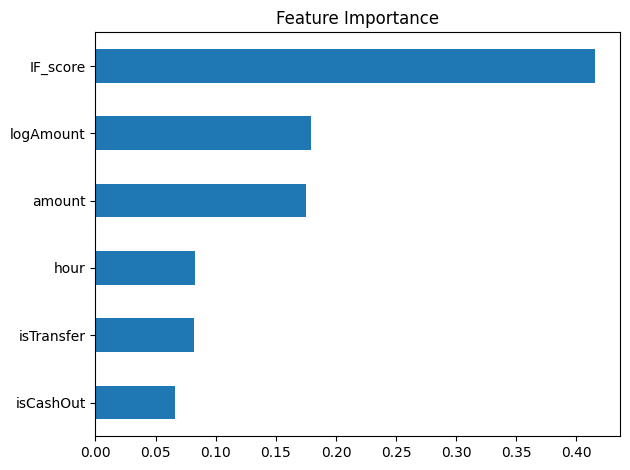

In [ ]:
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced")
rf.fit(X_train_hybrid, y_train)

importances = rf.feature_importances_

features = [
    "amount",
    "logAmount",
    "hour",
    "isTransfer",
    "isCashOut",
    "IF_score"
]

pd.Series(importances, index=features).sort_values().plot(kind="barh")

plt.title("Feature Importance")
plt.tight_layout()
plt.show()

ROC CURVE COMPARISON


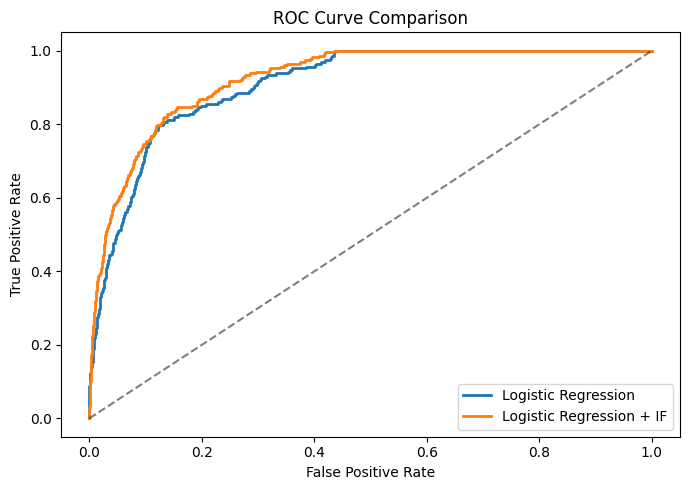

In [ ]:
# ROC Curve: Baseline vs Hybrid Logistic Regression
from sklearn.metrics import roc_curve

print("="*60)
print("ROC CURVE COMPARISON")
print("="*60)

# Train baseline LR
lr_baseline = LogisticRegression(
    max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE
)
lr_baseline.fit(X_train_scaled, y_train)
y_prob_lr = lr_baseline.predict_proba(X_test_scaled)[:, 1]

# Train hybrid LR
lr_hybrid = LogisticRegression(
    max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE
)
lr_hybrid.fit(X_train_hybrid, y_train)
y_prob_lr_if = lr_hybrid.predict_proba(X_test_hybrid)[:, 1]

# ROC curve data
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_lr_if, tpr_lr_if, _ = roc_curve(y_test, y_prob_lr_if)

# Plot
plt.figure(figsize=(7,5))
plt.plot(fpr_lr, tpr_lr, label='Logistic Regression', linewidth=2)
plt.plot(fpr_lr_if, tpr_lr_if, label='Logistic Regression + IF', linewidth=2)
plt.plot([0,1], [0,1], 'k--', alpha=0.5)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.tight_layout()
plt.savefig('fig_roc_lr_vs_lr_if.png', dpi=150)
plt.show()

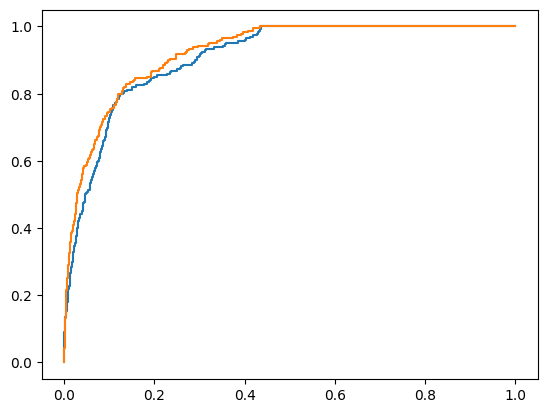

In [ ]:
plt.plot(fpr_lr, tpr_lr,
         label=f'Logistic Regression (AUC = {roc_auc_score(y_test,y_prob_lr):.3f})')

plt.plot(fpr_lr_if, tpr_lr_if,
         label=f'Logistic Regression + IF (AUC = {roc_auc_score(y_test,y_prob_lr_if):.3f})')

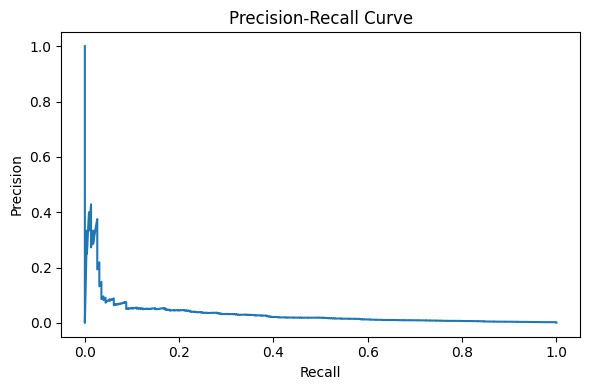

In [ ]:
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(y_test, y_prob_lr_if)

plt.figure(figsize=(6,4))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.tight_layout()
plt.show()

CONFUSION MATRIX ANALYSIS


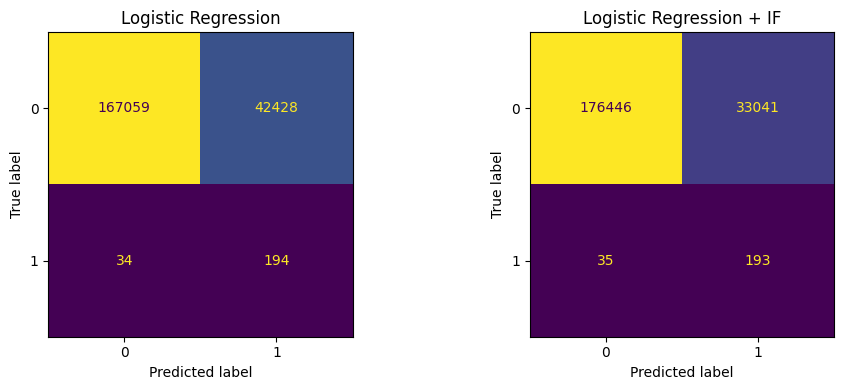

In [ ]:
# Confusion Matrix: Baseline vs Hybrid Logistic Regression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("="*60)
print("CONFUSION MATRIX ANALYSIS")
print("="*60)

# Predictions
y_pred_lr = lr_baseline.predict(X_test_scaled)
y_pred_lr_if = lr_hybrid.predict(X_test_hybrid)

# Confusion matrices
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_lr_if = confusion_matrix(y_test, y_pred_lr_if)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(10,4))

ConfusionMatrixDisplay(cm_lr).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay(cm_lr_if).plot(ax=axes[1], colorbar=False)
axes[1].set_title("Logistic Regression + IF")

plt.tight_layout()
plt.savefig("fig_confusion_matrix_lr_vs_lr_if.png", dpi=150)
plt.show()

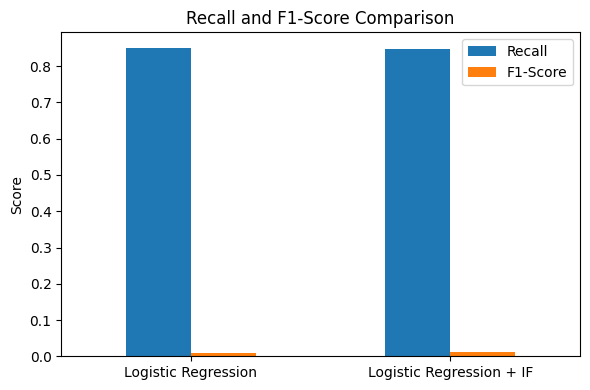

In [ ]:
# Recall and F1 Comparison
metrics_compare = comparison_df.loc[
    ['Logistic Regression', 'Logistic Regression + IF'],
    ['Recall', 'F1-Score']
]

metrics_compare.plot(kind='bar', figsize=(6,4))
plt.title('Recall and F1-Score Comparison')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('fig_recall_f1_comparison.png', dpi=150)
plt.show()

In [ ]:
RANDOM_STATE = 42
# Stratified K-Fold Cross Validation
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression # Added this import

print("="*60)
print("STRATIFIED K-FOLD VALIDATION")
print("="*60)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cross_val_auc(model, X, y):
    aucs = []
    for train_idx, test_idx in skf.split(X, y):
        model.fit(X[train_idx], y.iloc[train_idx])
        y_prob = model.predict_proba(X[test_idx])[:, 1]
        aucs.append(roc_auc_score(y.iloc[test_idx], y_prob))
    return aucs # Return the list of AUCs

# Baseline
baseline_scores = cross_val_auc(
    LogisticRegression(max_iter=1000, class_weight='balanced'),
    X_train_scaled, y_train
)

# Hybrid
hybrid_scores = cross_val_auc(
    LogisticRegression(max_iter=1000, class_weight='balanced'),
    X_train_hybrid, y_train
)

auc_lr_mean, auc_lr_std = np.mean(baseline_scores), np.std(baseline_scores)
auc_lr_if_mean, auc_lr_if_std = np.mean(hybrid_scores), np.std(hybrid_scores)

print(f"Baseline LR ROC-AUC: {auc_lr_mean:.4f} \u00b1 {auc_lr_std:.4f}")
print(f"Hybrid LR + IF ROC-AUC: {auc_lr_if_mean:.4f} \u00b1 {auc_lr_if_std:.4f}")

STRATIFIED K-FOLD VALIDATION
Baseline LR ROC-AUC: 0.9156 ± 0.0070
Hybrid LR + IF ROC-AUC: 0.9387 ± 0.0045


In [ ]:
from scipy.stats import ttest_rel

t_stat, p_value = ttest_rel(baseline_scores, hybrid_scores)

print("P-value:", p_value)

P-value: 0.006894847801991053
